In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

df = pd.read_csv("rainfalldata_2001_to_2025.csv")
df
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9422 entries, 0 to 9421
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   YEAR         9422 non-null   int64  
 1   DOY          9422 non-null   int64  
 2   PRECTOTCORR  9422 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 221.0 KB


In [2]:
df.describe()

,YEAR,DOY,PRECTOTCORR
count,9422.000000,9422.000000,9422.000000
mean,2013.402144,181.973785,2.638204
std,7.446809,105.041493,8.345573
min,2001.000000,1.000000,0.000000
25%,2007.000000,91.000000,0.000000
50%,2013.000000,182.000000,0.000000
75%,2020.000000,272.000000,1.000000
max,2026.000000,366.000000,189.450000


In [3]:
df.isna().sum()

YEAR           0
DOY            0
PRECTOTCORR    0
dtype: int64

In [4]:
df.duplicated().sum()


np.int64(0)

In [5]:
df.dtypes

YEAR             int64
DOY              int64
PRECTOTCORR    float64
dtype: object

In [6]:
# Checking validation of years 
df[(df['YEAR'] < 2001) | (df['YEAR'] > 2026)]

,YEAR,DOY,PRECTOTCORR


In [7]:
# Checking validation of Doy 
df[(df['DOY'] < 1) | (df['DOY'] > 366)]

,YEAR,DOY,PRECTOTCORR


In [8]:
# Checking validation of PRECTOTCORR

df[df['DOY'] < 0]

,YEAR,DOY,PRECTOTCORR


In [9]:
# Making new columns is rain falls or not
df['Rainy_Day'] = np.where(df['PRECTOTCORR'] > 0, "Yes","No")
df

,YEAR,DOY,PRECTOTCORR,Rainy_Day
0,2001,1,0.03,Yes
1,2001,2,0.00,No
2,2001,3,0.00,No
3,2001,4,0.00,No
4,2001,5,0.00,No
...,...,...,...,...
9417,2026,287,0.08,Yes
9418,2026,288,0.00,No
9419,2026,289,0.26,Yes
9420,2026,290,0.00,No


In [10]:
# Deciding Rain type According to the PRECTOTCORR (mm)
rain_conditions = {
    "Rain Types": [
        "No Rain",
        "Very Light",
        "Light",
        "Moderate",
        "Heavy",
        "Very Heavy",
        "Extremely Heavy"
    ],
    "Condition": [
        "0 mm",
        "0.1 to 2.4 mm",
        "2.5 to 15.5 mm",
        "15.6 to 64.4 mm",
        "64.5 to 115.5 mm",
        "115.6 to 204.4 mm",
        "204.5 mm or more"
    ]
}



rain_con = pd.DataFrame(rain_conditions )
rain_con


rain_prep = {
    "NO rain" : 0.1 
}

In [11]:
# Making Rain types column
df["Rain_Type"] = np.where(
    df['PRECTOTCORR'] >= 204.5,"Extremely heavy",np.where(
        df['PRECTOTCORR'] >= 115.6,"Very heavy",np.where(
            df['PRECTOTCORR'] >= 64.5,"Heavy",np.where(
                df['PRECTOTCORR'] >= 15.6,"Moderate",np.where(
                    df['PRECTOTCORR'] >= 2.5,"Light",np.where(
                        df['PRECTOTCORR'] >= 0.1,"Very light","No Precipitation recorded"
                    )
                )
            )
        )
    )
)
df

,YEAR,DOY,PRECTOTCORR,Rainy_Day,Rain_Type
0,2001,1,0.03,Yes,No Precipitation recorded
1,2001,2,0.00,No,No Precipitation recorded
2,2001,3,0.00,No,No Precipitation recorded
3,2001,4,0.00,No,No Precipitation recorded
4,2001,5,0.00,No,No Precipitation recorded
...,...,...,...,...,...
9417,2026,287,0.08,Yes,No Precipitation recorded
9418,2026,288,0.00,No,No Precipitation recorded
9419,2026,289,0.26,Yes,Very light
9420,2026,290,0.00,No,No Precipitation recorded


In [12]:
df.shape

(9422, 5)

In [13]:
# Checking Overall rainfall Days How much days is fall or not in percentage
df['Rainy_Day'].value_counts(normalize=True) * 100

Rainy_Day
No     56.410529
Yes    43.589471
Name: proportion, dtype: float64

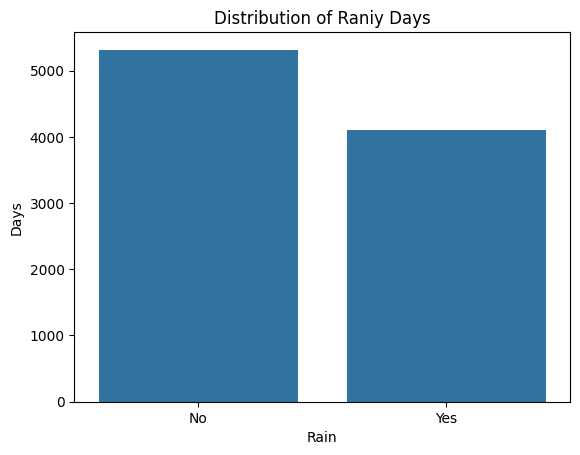

In [14]:
# Makeing Graph of rainy Days in 2001 - 2026 years

rain = df['Rainy_Day'].value_counts() 

sns.barplot(
    x = rain.index,
    y = rain.values
)
plt.title("Distribution of Raniy Days")
plt.xlabel("Rain")
plt.ylabel("Days")

plt.show()

In [15]:
# Making new column Date 
df["Date"] = pd.to_datetime(df['YEAR'].astype(str) + '-01-01') + pd.to_timedelta(df['DOY'] - 1, unit = "D")
df

,YEAR,DOY,PRECTOTCORR,Rainy_Day,Rain_Type,Date
0,2001,1,0.03,Yes,No Precipitation recorded,2001-01-01
1,2001,2,0.00,No,No Precipitation recorded,2001-01-02
2,2001,3,0.00,No,No Precipitation recorded,2001-01-03
3,2001,4,0.00,No,No Precipitation recorded,2001-01-04
4,2001,5,0.00,No,No Precipitation recorded,2001-01-05
...,...,...,...,...,...,...
9417,2026,287,0.08,Yes,No Precipitation recorded,2026-10-14
9418,2026,288,0.00,No,No Precipitation recorded,2026-10-15
9419,2026,289,0.26,Yes,Very light,2026-10-16
9420,2026,290,0.00,No,No Precipitation recorded,2026-10-17


In [16]:
# Making new column Day Name 
df["Day_Name"] = df["Date"].dt.day_name()
df

,YEAR,DOY,PRECTOTCORR,Rainy_Day,Rain_Type,Date,Day_Name
0,2001,1,0.03,Yes,No Precipitation recorded,2001-01-01,Monday
1,2001,2,0.00,No,No Precipitation recorded,2001-01-02,Tuesday
2,2001,3,0.00,No,No Precipitation recorded,2001-01-03,Wednesday
3,2001,4,0.00,No,No Precipitation recorded,2001-01-04,Thursday
4,2001,5,0.00,No,No Precipitation recorded,2001-01-05,Friday
...,...,...,...,...,...,...,...
9417,2026,287,0.08,Yes,No Precipitation recorded,2026-10-14,Wednesday
9418,2026,288,0.00,No,No Precipitation recorded,2026-10-15,Thursday
9419,2026,289,0.26,Yes,Very light,2026-10-16,Friday
9420,2026,290,0.00,No,No Precipitation recorded,2026-10-17,Saturday


Rain_Type
No Precipitation recorded    5980
Very light                   1668
Light                        1336
Moderate                      406
Heavy                          29
Very heavy                      3
Name: count, dtype: int64 



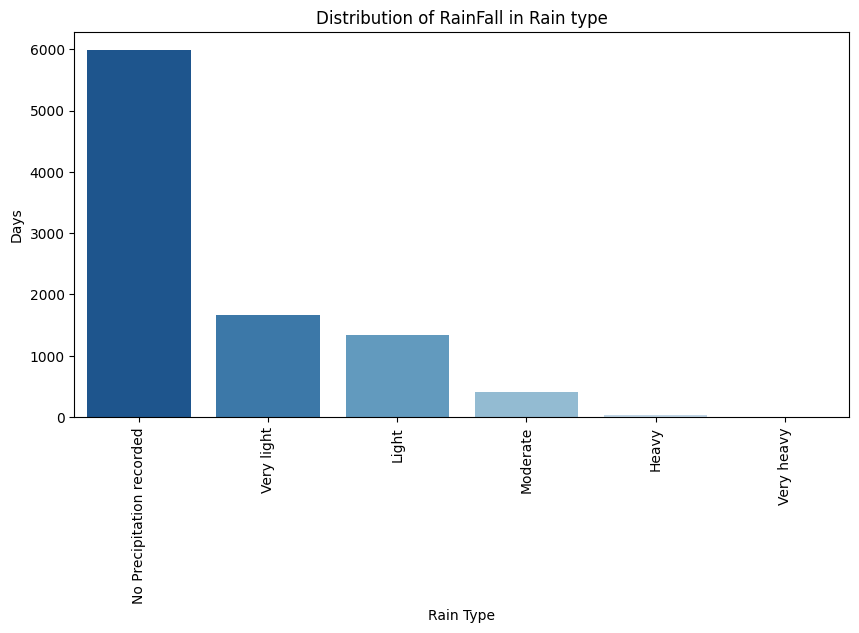

In [17]:
# Graph of Rainfall According to Rain_Type 
total = df['Rain_Type'].value_counts()
print(total,"\n")
plt.figure(figsize=(10,5))
sns.barplot(
    x = total.index,
    y = total.values,
    hue = total.index,
    palette = "Blues_r"
)
plt.title("Distribution of RainFall in Rain type")
plt.xlabel("Rain Type")
plt.ylabel("Days")
plt.xticks(rotation=90)
plt.show()

Rain_Type
No Precipitation recorded    63.468478
Very light                   17.703248
Light                        14.179580
Moderate                      4.309064
Heavy                         0.307790
Very heavy                    0.031840
Name: proportion, dtype: float64 



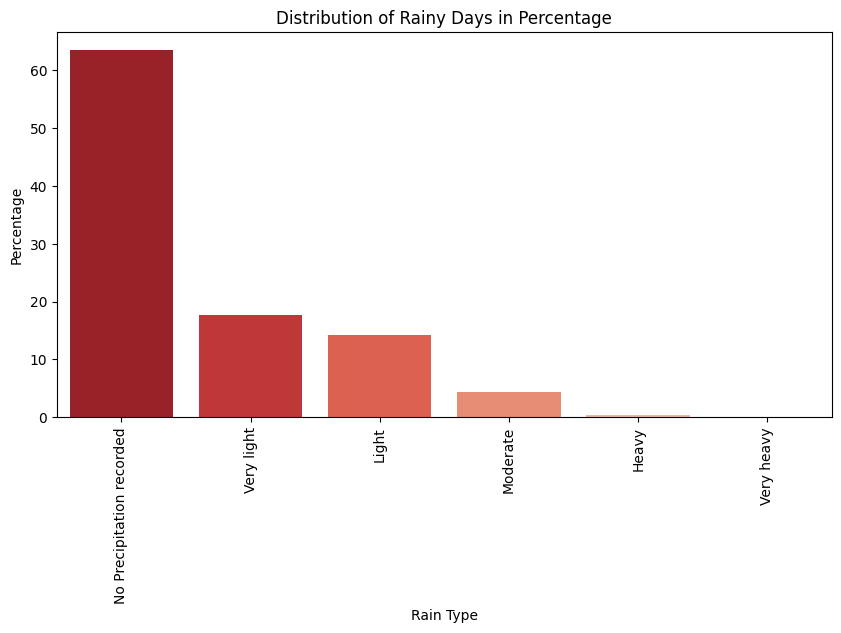

In [18]:
# Graph of Rainy Days According to Rain_Type 
total = df['Rain_Type'].value_counts(normalize=True) * 100
print(total,"\n")
plt.figure(figsize=(10,5))
sns.barplot(
    x = total.index,
    y = total.values,
    hue = total.index,
    palette = "Reds_r"
)
plt.title("Distribution of Rainy Days in Percentage")
plt.xlabel("Rain Type")
plt.ylabel("Percentage")
plt.xticks(rotation=90)
plt.show()

In [19]:
# Making pivot table of Year and Rain types 
pd.pivot_table(data = df, index='YEAR', columns='Rain_Type', aggfunc='size', fill_value=0)

Rain_Type,Heavy,Light,Moderate,No Precipitation recorded,Very heavy,Very light
YEAR,,,,,,
2001,0,43,6,236,0,80
2002,0,43,9,258,0,55
2003,2,51,19,233,0,60
2004,1,39,16,238,0,72
2005,3,46,9,234,0,73
2006,1,52,21,209,0,82
2007,1,46,17,242,0,59
2008,0,48,7,243,0,68
2009,2,31,18,238,0,76


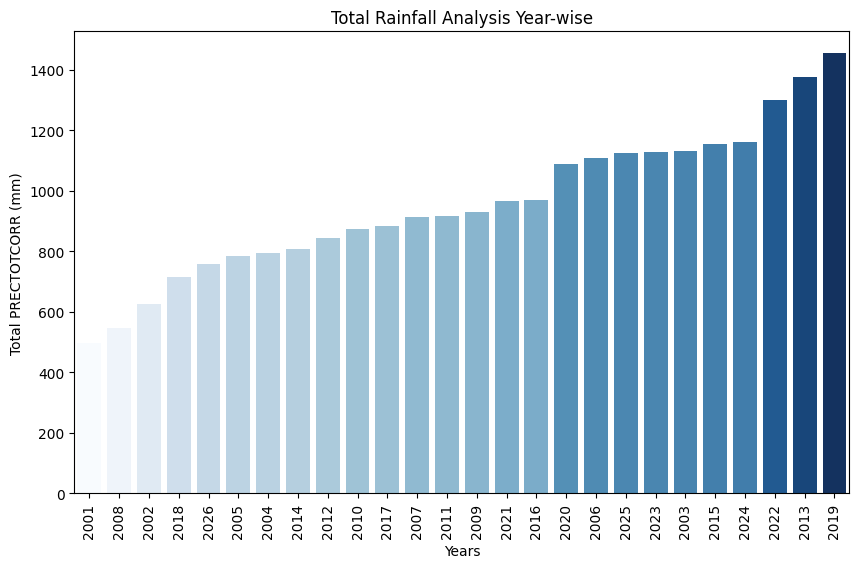

In [20]:
# Making Barplot of total total rainfall Year - wise 
total = df.groupby('YEAR')['PRECTOTCORR'].sum().sort_values(ascending = True)
plt.figure(figsize=(10,6))
sns.barplot(
    x = total.index,
    y = total.values,
    order = total.index,
    hue = total.values,
    palette = 'Blues',
    legend = False
)
plt.title("Total Rainfall Analysis Year-wise")
plt.xlabel("Years")
plt.ylabel("Total PRECTOTCORR (mm)")
plt.xticks(rotation = 90)
plt.show()


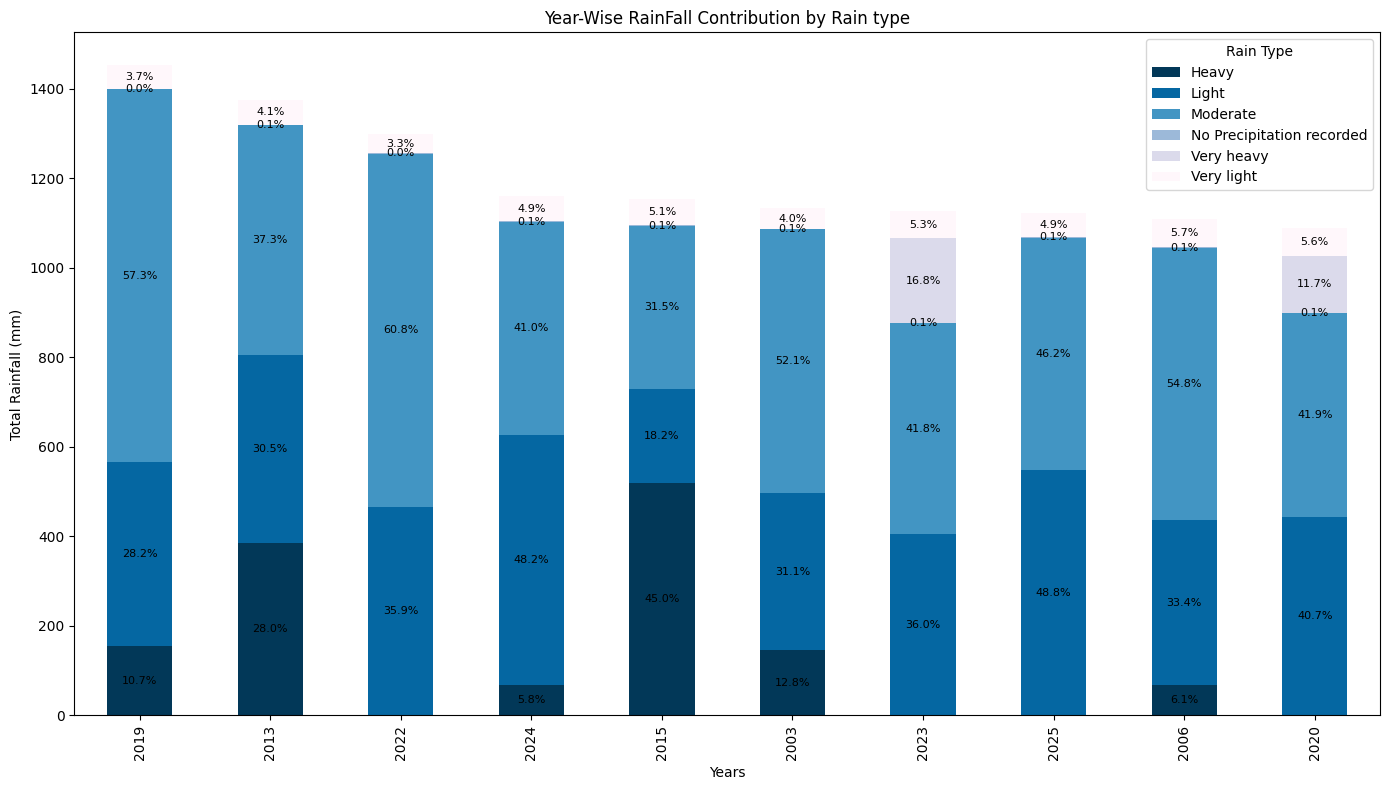

In [21]:
# Making Barplot of Total rainfall year-wise and also rain types
rain_type_rain = df.pivot_table(
    index = 'YEAR',
    columns = 'Rain_Type',
    values = 'PRECTOTCORR',
    aggfunc = 'sum',
    fill_value = 0
)

rain_type_rain = rain_type_rain.loc[
    rain_type_rain.sum(axis=1).sort_values(ascending=False).head(10).index
]

rain_type_pct = rain_type_rain.div(
    rain_type_rain.sum(axis=1), axis=0
)*100

ax = rain_type_rain.plot(
    kind = 'bar',
    stacked = True,
    figsize = (14,8),
    colormap = 'PuBu_r'
)

for i, year in enumerate(rain_type_rain.index):
    bottom = 0

    for rain_type in rain_type_rain.columns:
        value = rain_type_rain.loc[year, rain_type]
        pct = rain_type_pct.loc[year, rain_type]

        if value > 0:
            ax.text(
                i,
                bottom + value / 2,
                f'{pct:.1f}%',
                ha = 'center',
                va = 'center',
                fontsize=8                
            )

        bottom += value

plt.title("Year-Wise RainFall Contribution by Rain type")
plt.xlabel("Years")
plt.ylabel("Total Rainfall (mm)")
plt.xticks(rotation=90)
plt.legend(title='Rain Type')
plt.tight_layout()
plt.show()

Rain_Type
No Precipitation recorded    5980
Very light                   1668
Light                        1336
Moderate                      406
Heavy                          29
Very heavy                      3
Name: count, dtype: int64


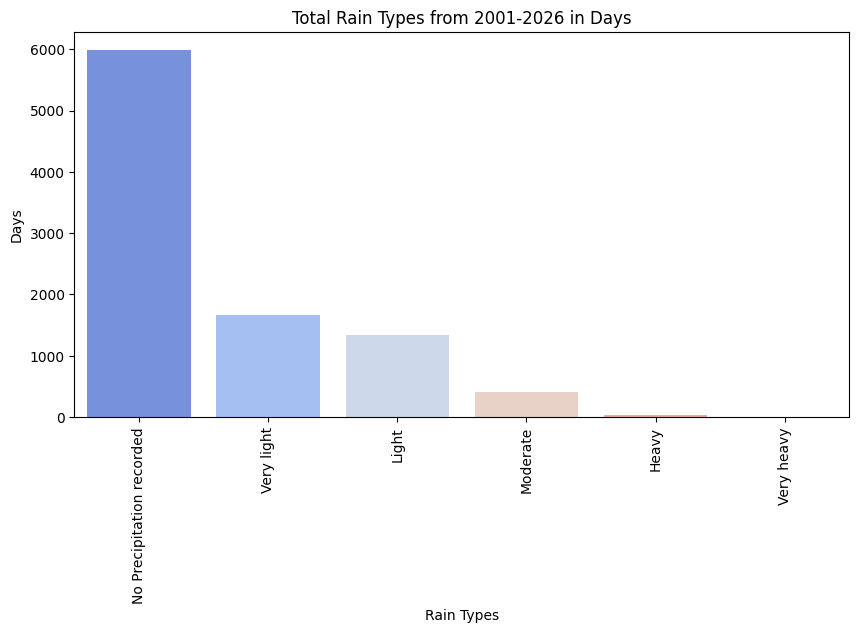

In [22]:
# Making barplot of rain types 
total = df['Rain_Type'].value_counts()
print(total)
plt.figure(figsize=(10,5))
sns.barplot(
    x = total.index,
    y = total.values,
    hue = total.index,
    palette = 'coolwarm'
)
plt.title("Total Rain Types from 2001-2026 in Days")
plt.xlabel("Rain Types")
plt.ylabel("Days")
plt.xticks(rotation=90)
plt.show()

Rain_Type
No Precipitation recorded    63.47
Very light                   17.70
Light                        14.18
Moderate                      4.31
Heavy                         0.31
Very heavy                    0.03
Name: proportion, dtype: float64


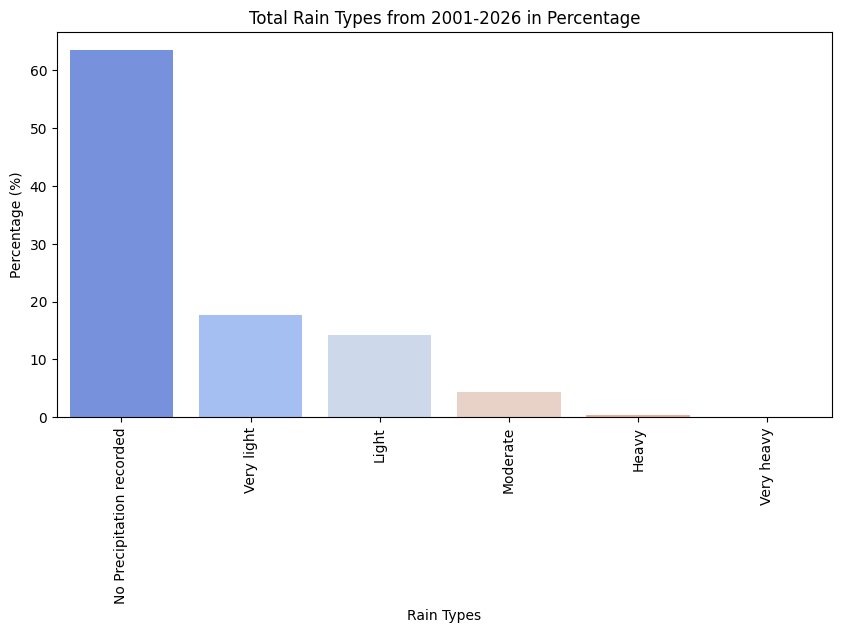

In [23]:
# Making barplot of rain types in percentage
total = df['Rain_Type'].value_counts(normalize = True) * 100
print(round(total,2))
plt.figure(figsize=(10,5))
sns.barplot(
    x = total.index,
    y = total.values,
    hue = total.index,
    palette = 'coolwarm'
)
plt.title("Total Rain Types from 2001-2026 in Percentage")
plt.xlabel("Rain Types")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=90)
plt.show()

In [24]:
rain_con

,Rain Types,Condition
0,No Rain,0 mm
1,Very Light,0.1 to 2.4 mm
2,Light,2.5 to 15.5 mm
3,Moderate,15.6 to 64.4 mm
4,Heavy,64.5 to 115.5 mm
5,Very Heavy,115.6 to 204.4 mm
6,Extremely Heavy,204.5 mm or more


Overall Heavy Rains :  29 

      YEAR  PRECTOTCORR Rain_Type       Date   Day_Name
902   2003        70.95     Heavy 2003-06-22     Sunday
937   2003        74.56     Heavy 2003-07-27     Sunday
1330  2004        81.43     Heavy 2004-08-23     Monday
1668  2005        91.19     Heavy 2005-07-27  Wednesday
1672  2005       100.45     Heavy 2005-07-31     Sunday
1717  2005        65.12     Heavy 2005-09-14  Wednesday
2044  2006        67.20     Heavy 2006-08-07     Monday
2379  2007        80.30     Heavy 2007-07-08     Sunday
3124  2009       103.38     Heavy 2009-07-22  Wednesday
3125  2009        94.53     Heavy 2009-07-23   Thursday
3886  2011        97.12     Heavy 2011-08-23    Tuesday
4266  2012        77.83     Heavy 2012-09-06   Thursday
4541  2013        72.45     Heavy 2013-06-08   Saturday
4566  2013       102.74     Heavy 2013-07-03  Wednesday
4567  2013        66.13     Heavy 2013-07-04   Thursday
4589  2013        70.26     Heavy 2013-07-26     Friday
4617  2013        74

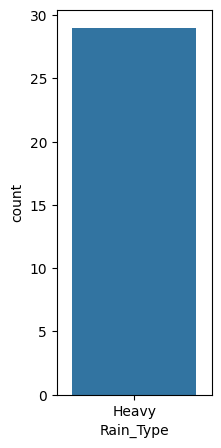

In [25]:
# Analysising how much time Heavy rain appear each year
print("Overall Heavy Rains : ",df[df['Rain_Type'] == 'Heavy']['Rain_Type'].count(),"\n")
heavy = df[df['Rain_Type'] == 'Heavy'][[
    'YEAR','PRECTOTCORR','Rain_Type','Date','Day_Name'
]].head(30)
print(heavy)
plt.figure(figsize=(2,5))
sns.countplot(
    data = heavy,
    x = 'Rain_Type'
)
plt.xticks(rotation=0)
plt.show()

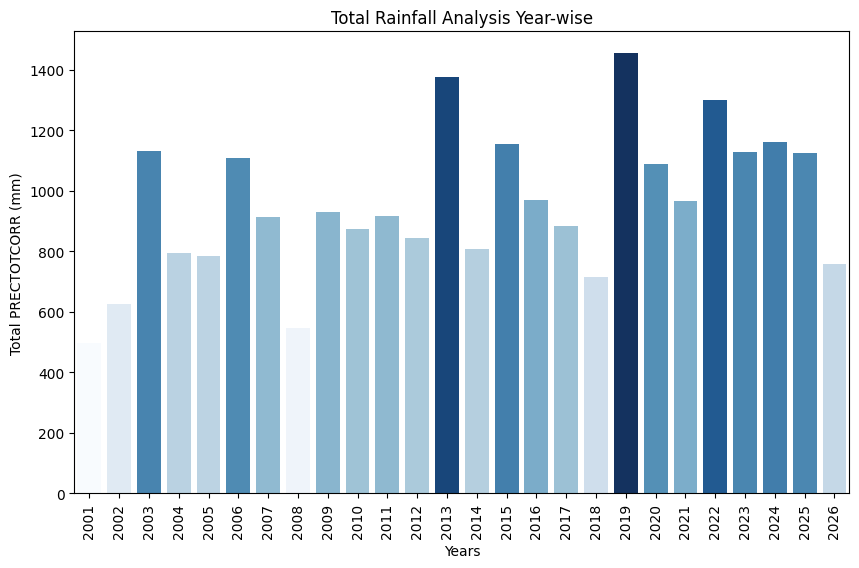

In [26]:
# Total rainfall year wise 
total = df.groupby('YEAR')['PRECTOTCORR'].sum()
plt.figure(figsize=(10,6))
sns.barplot(
    x = total.index,
    y = total.values,
    order = total.index,
    hue = total.values,
    palette = 'Blues',
    legend = False
)
plt.title("Total Rainfall Analysis Year-wise")
plt.xlabel("Years")
plt.ylabel("Total PRECTOTCORR (mm)")
plt.xticks(rotation = 90)
plt.show()


Rain_Type   Heavy   Light  Moderate  No Precipitation recorded  Very heavy  \
YEAR                                                                         
2001          NaN  250.68    177.75                       1.30         NaN   
2002          NaN  321.58    264.99                       0.73         NaN   
2003       145.51  351.97    589.92                       0.61         NaN   
2004        81.43  241.75    412.86                       1.14         NaN   
2005       256.76  267.50    200.48                       1.08         NaN   
2006        67.20  370.08    607.84                       0.89         NaN   
2007        80.30  318.62    461.13                       0.95         NaN   
2008          NaN  341.50    144.15                       1.01         NaN   
2009       197.91  196.08    472.99                       1.07         NaN   
2010          NaN  355.17    437.51                       1.38         NaN   
2011        97.12  371.74    411.31                       0.93  

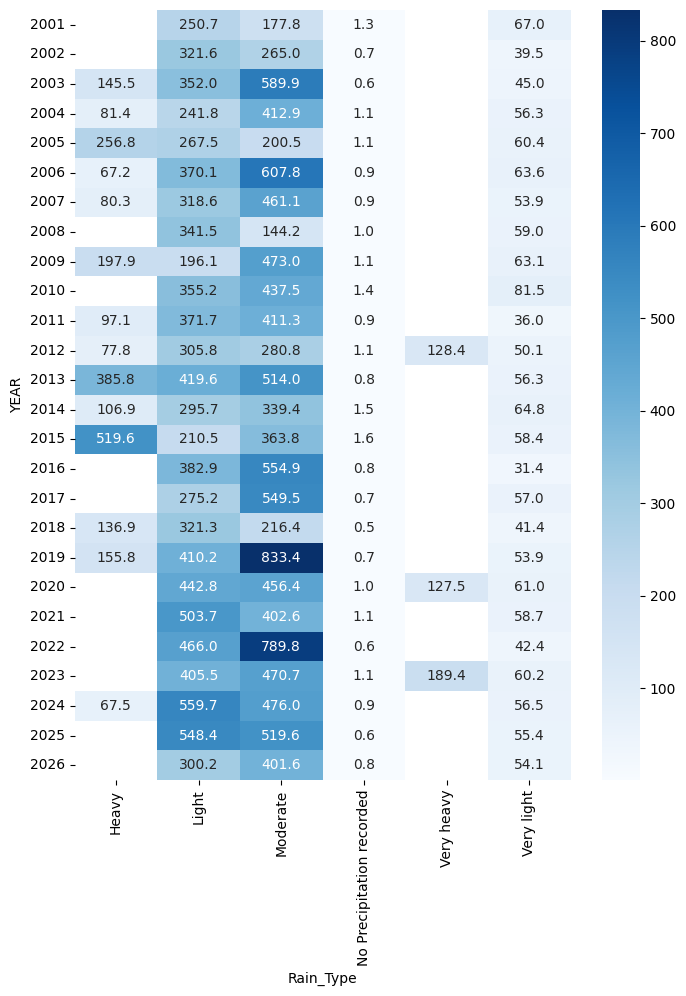

In [27]:
# Making Heatmap of Rainfall
matrix_df = df.pivot_table(
    index = 'YEAR',
    columns = 'Rain_Type',
    values = 'PRECTOTCORR',
    aggfunc = 'sum'
)
print(matrix_df)
plt.figure(figsize=(8,10))
sns.heatmap(
    matrix_df,
    cmap = 'Blues',
    annot = True,
    fmt = '.1f'
)
plt.show()

In [28]:
# Making new columns Month 
df['Month'] = df['Date'].dt.strftime('%B')
df.head()

,YEAR,DOY,PRECTOTCORR,Rainy_Day,Rain_Type,Date,Day_Name,Month
0,2001,1,0.03,Yes,No Precipitation recorded,2001-01-01,Monday,January
1,2001,2,0.00,No,No Precipitation recorded,2001-01-02,Tuesday,January
2,2001,3,0.00,No,No Precipitation recorded,2001-01-03,Wednesday,January
3,2001,4,0.00,No,No Precipitation recorded,2001-01-04,Thursday,January
4,2001,5,0.00,No,No Precipitation recorded,2001-01-05,Friday,January


Month
January       121.21
February       78.54
March         151.80
April         118.99
May           396.08
June         3401.70
July         7550.51
August       6956.44
September    4817.47
October       851.66
November      297.59
December      115.17
Name: PRECTOTCORR, dtype: float64


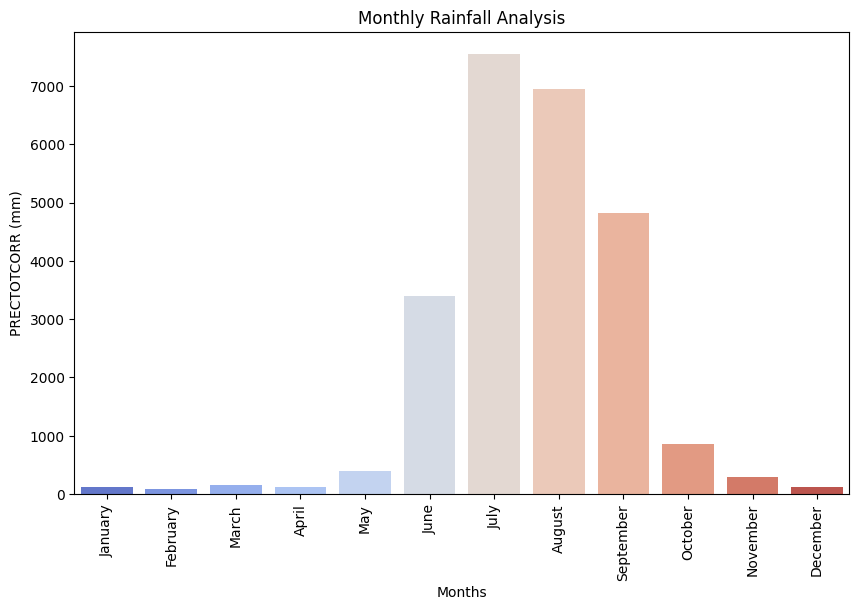

In [29]:
# Overall Rainfall Monthly Analysis 
total = df.groupby(['Month'])['PRECTOTCORR'].sum().sort_index()
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]
total = total.reindex(month_order)
print(total)
plt.figure(figsize=(10,6))
sns.barplot(
    x = total.index,
    y = total.values,
    hue = total.index,
    palette = 'coolwarm'
)
plt.title("Monthly Rainfall Analysis")
plt.xlabel("Months")
plt.ylabel("PRECTOTCORR (mm)")
plt.xticks(rotation=90)
plt.show()

Month  January  February  March  April     May    June    July  August  \
YEAR                                                                     
2001      0.03      0.09   3.89   1.38   23.01  158.04  134.20  102.77   
2002      0.05     13.67   5.94  17.74    3.63  166.99   34.78  290.51   
2003      1.45     13.16   0.13   0.57    3.80  206.36  365.35  185.09   
2004      5.69      0.00   0.16   0.12   13.19   64.34  246.19  298.54   
2005      5.65      0.23   4.55   2.33    4.05  101.60  332.87  108.37   
2006      0.00      0.03  29.38   0.58   41.50   98.78  275.62  421.66   
2007      1.96      5.12   0.03   8.10   33.56  135.83  317.86  285.29   
2008      0.61      0.03   1.63   0.75    0.85  109.18  145.75  150.46   
2009      2.01      0.00   9.65   0.20   15.99   80.25  374.93  150.93   
2010      2.26      2.61   1.13   0.04    4.31   98.12  137.96  350.17   
2011      0.00      0.81   0.42   1.44    0.78   72.57  219.66  515.58   
2012      0.54      0.00   0.00   1.23

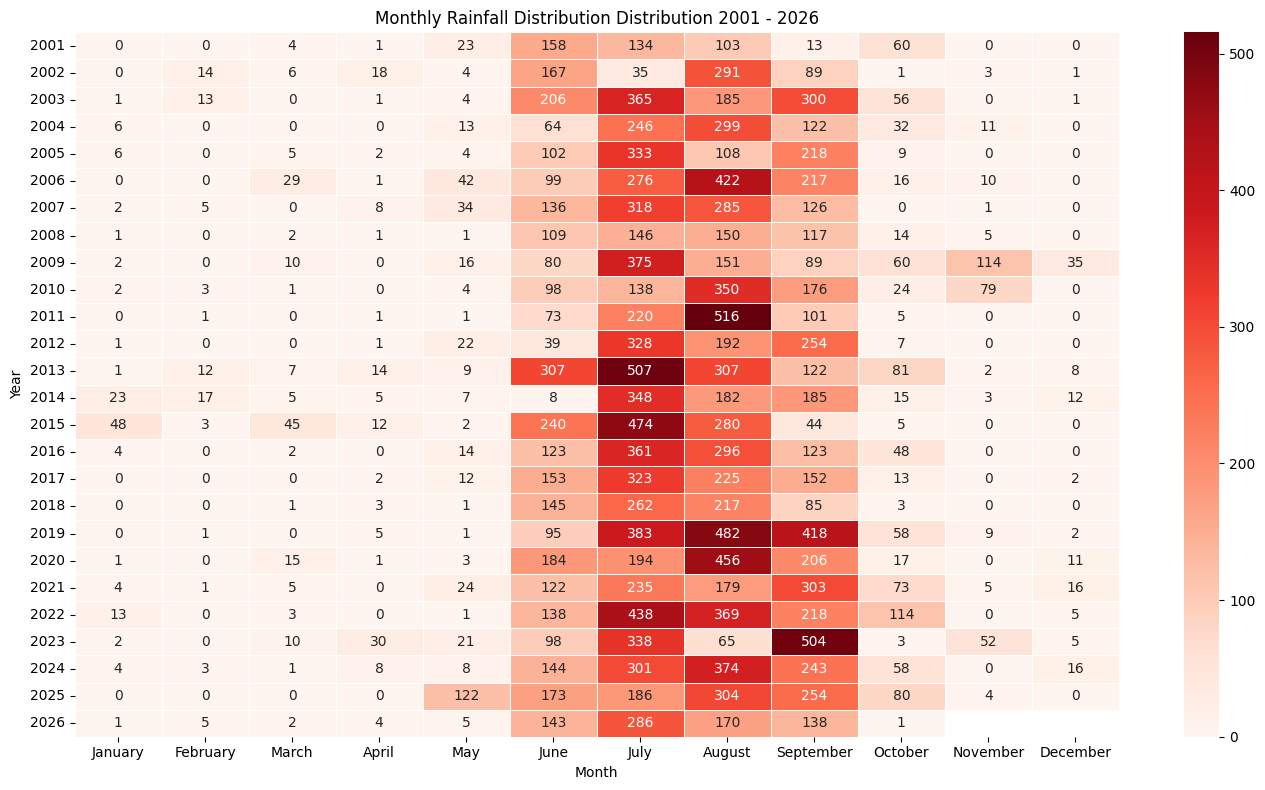

In [30]:
# Monthly Rainfall Distribution 2001 - 2026

total = df.groupby(['YEAR','Month'])['PRECTOTCORR'].sum().sort_index()
data = pd.DataFrame(total)
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]
data = data.reset_index()
data['Month'] = pd.Categorical(
    data['Month'],
    categories = month_order,
    ordered = True
)

data = data.sort_values(['YEAR','Month'])

monthly_matrix = data.pivot(
    index = 'YEAR',
    columns = 'Month',
    values = 'PRECTOTCORR'
)

print(monthly_matrix)

plt.figure(figsize=(14,8))

sns.heatmap(
    monthly_matrix,
    cmap = "Reds",
    annot = True,
    fmt = '.0f',
    linewidths = 0.5
)

plt.title("Monthly Rainfall Distribution Distribution 2001 - 2026")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

Rainy_Day
No     56.410529
Yes    43.589471
Name: proportion, dtype: float64 




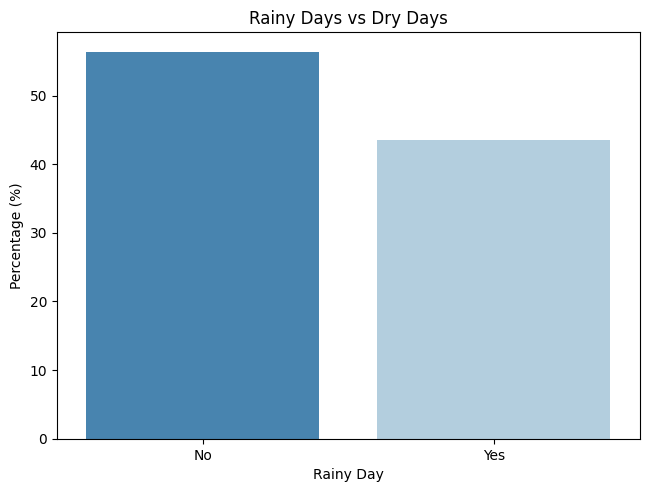

In [31]:
total = df['Rainy_Day'].value_counts(normalize=True)*100
print(total,"\n\n")
sns.barplot(
    x = total.index,
    y = total.values,
    hue = total.index,
    palette = "Blues_r"
)
plt.tight_layout()
plt.title("Rainy Days vs Dry Days")
plt.xlabel("Rainy Day")
plt.ylabel("Percentage (%)")
plt.show()

In [32]:
df.head(10)

,YEAR,DOY,PRECTOTCORR,Rainy_Day,Rain_Type,Date,Day_Name,Month
0,2001,1,0.03,Yes,No Precipitation recorded,2001-01-01,Monday,January
1,2001,2,0.00,No,No Precipitation recorded,2001-01-02,Tuesday,January
2,2001,3,0.00,No,No Precipitation recorded,2001-01-03,Wednesday,January
3,2001,4,0.00,No,No Precipitation recorded,2001-01-04,Thursday,January
4,2001,5,0.00,No,No Precipitation recorded,2001-01-05,Friday,January
5,2001,6,0.00,No,No Precipitation recorded,2001-01-06,Saturday,January
6,2001,7,0.00,No,No Precipitation recorded,2001-01-07,Sunday,January
7,2001,8,0.00,No,No Precipitation recorded,2001-01-08,Monday,January
8,2001,9,0.00,No,No Precipitation recorded,2001-01-09,Tuesday,January
9,2001,10,0.00,No,No Precipitation recorded,2001-01-10,Wednesday,January


    Dry_Days  Years
0         82   2016
1         79   2025
2         77   2001
3         72   2022
4         72   2011
5         67   2005
6         65   2012
7         64   2024
8         58   2006
9         58   2004
10        56   2009
11        53   2003
12        51   2017
13        47   2010
14        47   2008
15        45   2007
16        44   2020
17        43   2019
18        41   2018
19        36   2023
20        36   2021
21        35   2014
22        34   2002
23        29   2015
24        26   2026
25        21   2013


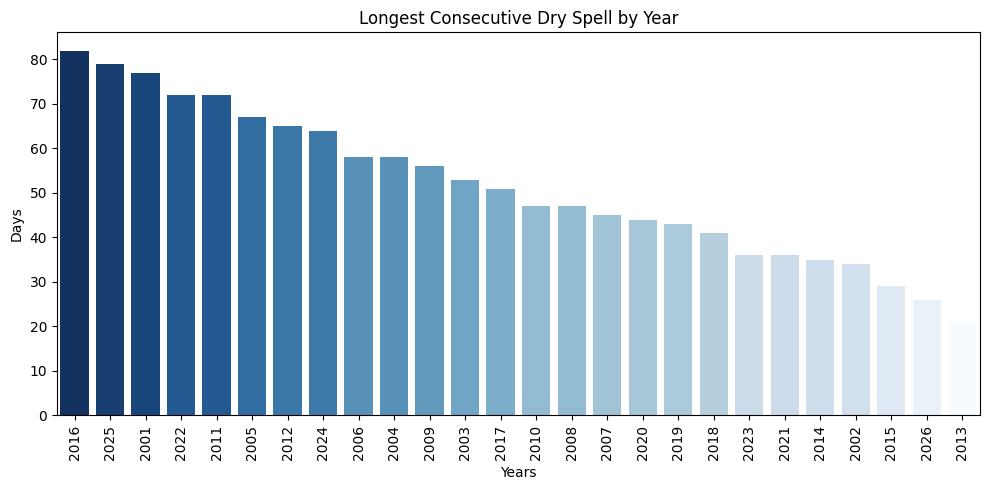

In [33]:
# Analysis Dry Spells of Overall Rainfall
dry_days = [] 
for year in df['YEAR'].unique():
    c = 0  
    l = 0

    y = df[df['YEAR'] == year]
    for r in y['PRECTOTCORR']:
        if r == 0:
            c += 1
        else:
            c = 0
        l = max(l, c)
    dry_days.append(l)
years = df['YEAR'].unique().tolist()

dry = {
    "Dry_Days" : dry_days,
    "Years" : years
}
dry = pd.DataFrame(dry)
dry = dry.sort_values(by='Dry_Days',ascending=False).reset_index(drop=True)
print(dry)
plt.figure(figsize=(10,5))
sns.barplot(
    data = dry,
    x = "Years",
    y = "Dry_Days",
    order = dry["Years"],
    hue = "Dry_Days",
    palette = 'Blues',
    legend = False
)
plt.title("Longest Consecutive Dry Spell by Year")
plt.xlabel("Years")
plt.ylabel("Days")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [34]:
l = 0
start_date = None
best_start = None
end_date = None
for i, r in enumerate(df['PRECTOTCORR']):
    if r == 0:
        c += 1

        if c == 1:
            start_date = df["Date"].iloc[i]

        if c > l:
            l = c
            best_start = start_date
            end_date = df["Date"].iloc[i]
        
    else:
        c = 0
print("longest Dry Spell : ",l)
print("Start Date : ",best_start)
print("End Date : ",end_date)


longest Dry Spell :  125
Start Date :  2005-10-26 00:00:00
End Date :  2006-02-27 00:00:00


          Start        End  Days
Rank                            
1    2005-10-26 2006-02-27   125
2    2016-10-11 2017-01-25   107
3    2025-11-04 2026-01-26    84
4    2001-10-16 2002-01-04    81
5    2025-01-13 2025-04-01    79
6    2011-10-20 2011-12-30    72
7    2022-03-12 2022-05-22    72
8    2017-12-08 2018-02-10    65
9    2012-01-31 2012-04-04    65
10   2018-12-10 2019-02-12    65 



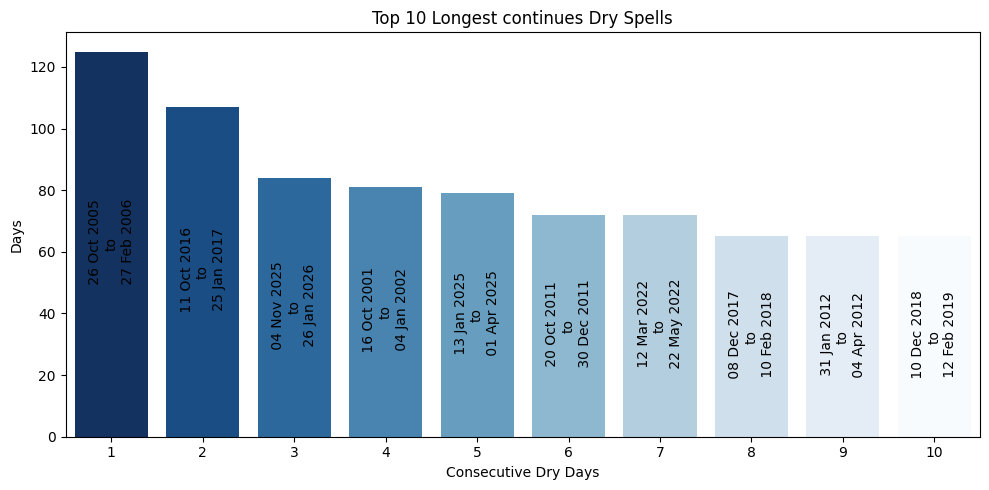

In [35]:
# Top10 Longest Dryseplls
dry_spell = []
start_date = None
c = 0
for i , r in enumerate(df['PRECTOTCORR']):
    if r == 0:
        if c == 0:
            start_date = df['Date'].iloc[i]
        c += 1

    else:
        if c > 0:
            dry_spell.append({
                "Start": start_date,
                "End": df['Date'].iloc[i-1],
                "Days": c
            })

        c = 0
if c > 0:
        dry_spell.append({
            "Start": start_date,
            "End": df['Date'].iloc[-1],
            "Days": c
        })
dry_spell = pd.DataFrame(dry_spell)
top10 = dry_spell.sort_values(by='Days',ascending = False).head(10).reset_index(drop=True)
top10.index = top10.index + 1
top10.index.name = "Rank"
print(top10,"\n")

plt.figure(figsize=(10,5))
sns.barplot(
    data = top10,
    x = top10.index,
    y = 'Days',
    hue = top10.index,
    palette = 'Blues_r',
    legend = False
)

for rank, row in top10.iterrows():
    plt.text(
        rank - 1,
        row['Days']/2,
        f"{row['Start']: %d %b %Y}\nto\n{row['End']: %d %b %Y}",
        ha = "center",
        va = "center",
        rotation = 90,
        color = 'black',
        fontsize = 10
    )
plt.title("Top 10 Longest continues Dry Spells")
plt.xlabel("Ranks")
plt.xlabel("Consecutive Dry Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
# June to september Rainfall Analysis
months = [
    'June', 'July', 'August',
    'September'
]
june_to_sep = df[df['Month'].isin(months)]

monsoon_rainfall = june_to_sep.groupby('YEAR')['PRECTOTCORR'].sum().sort_values()
monsoon_rainfall

YEAR
2001     408.41
2008     522.11
2002     581.44
2009     695.39
2018     708.18
2014     722.13
2004     730.83
2026     737.51
2005     760.36
2010     762.19
2012     813.24
2021     837.77
2017     852.98
2007     865.14
2016     902.64
2011     908.78
2025     918.21
2023    1004.25
2006    1012.69
2015    1037.72
2020    1041.02
2003    1056.87
2024    1062.36
2022    1163.04
2013    1242.87
2019    1377.99
Name: PRECTOTCORR, dtype: float64

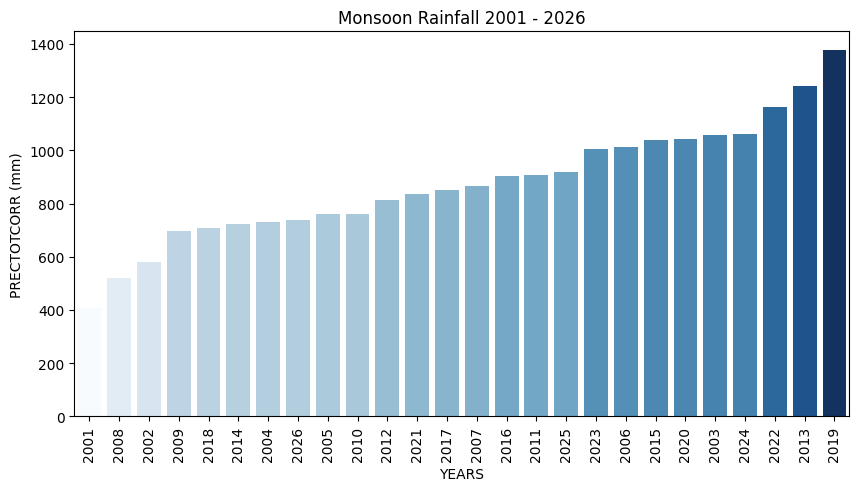

In [37]:
# june to September Mosoon Analysis 2001 - 2026

plt.figure(figsize=(10,5))
sns.barplot(
    x = monsoon_rainfall.index,
    y = monsoon_rainfall.values,
    order = monsoon_rainfall.index,
    hue = monsoon_rainfall.values,
    palette = "Blues",
    legend = False
)
plt.title("Monsoon Rainfall 2001 - 2026")
plt.xlabel("YEARS")
plt.ylabel("PRECTOTCORR (mm)")
plt.xticks(rotation=90)
plt.show()

Average Mosoon Rainfall(2001-2024):  874.08 



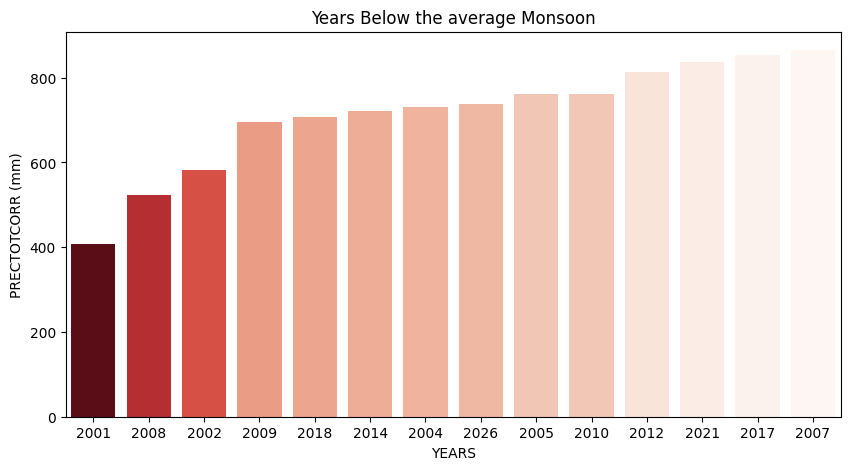




Average Mosoon Rainfall(2001-2024):  874.08 



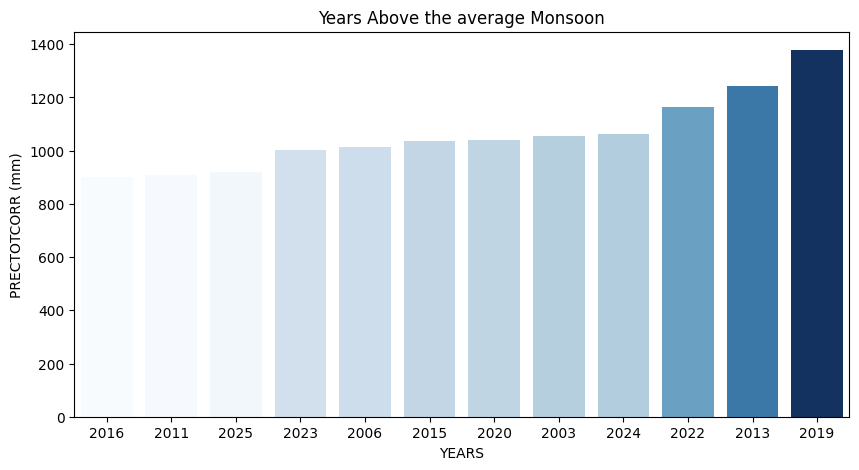

In [38]:
# june to September Average Mosoon Analysis 2001 - 2026
average_monsoon = monsoon_rainfall.mean()

below_average = monsoon_rainfall[monsoon_rainfall < average_monsoon]
above_average = monsoon_rainfall[monsoon_rainfall > average_monsoon]

print("Average Mosoon Rainfall(2001-2024): ", round(average_monsoon,2),"\n")
plt.figure(figsize=(10,5))
sns.barplot(
    x = below_average.index,
    y = below_average.values,
    order = below_average.index,
    hue = below_average.values,
    palette = "Reds_r",
    legend = False
)
plt.title("Years Below the average Monsoon")
plt.xlabel("YEARS")
plt.ylabel("PRECTOTCORR (mm)")
plt.show()

print("\n\n")

print("Average Mosoon Rainfall(2001-2024): ", round(average_monsoon,2),"\n")
plt.figure(figsize=(10,5))
sns.barplot(
    x = above_average.index,
    y = above_average.values,
    order = above_average.index,
    hue = above_average.values,
    palette = "Blues",
    legend = False
    
)
plt.title("Years Above the average Monsoon")
plt.xlabel("YEARS")
plt.ylabel("PRECTOTCORR (mm)")
plt.show()

YEAR
2001   -53.275526
2008   -40.267586
2002   -33.479890
2009   -20.443349
2018   -18.980099
2014   -17.384138
2004   -16.388807
2026   -15.624576
2005   -13.010404
2010   -12.801041
2012    -6.960625
2021    -4.154251
2017    -2.414138
2007    -1.022964
2016     3.267254
2011     3.969705
2025     5.048552
2023    14.892027
2006    15.857612
2015    18.721190
2020    19.098729
2003    20.912061
2024    21.540149
2022    33.058525
2013    42.191540
2019    57.650052
Name: PRECTOTCORR, dtype: float64 

Below Averge :  14
Above Averge :  12 



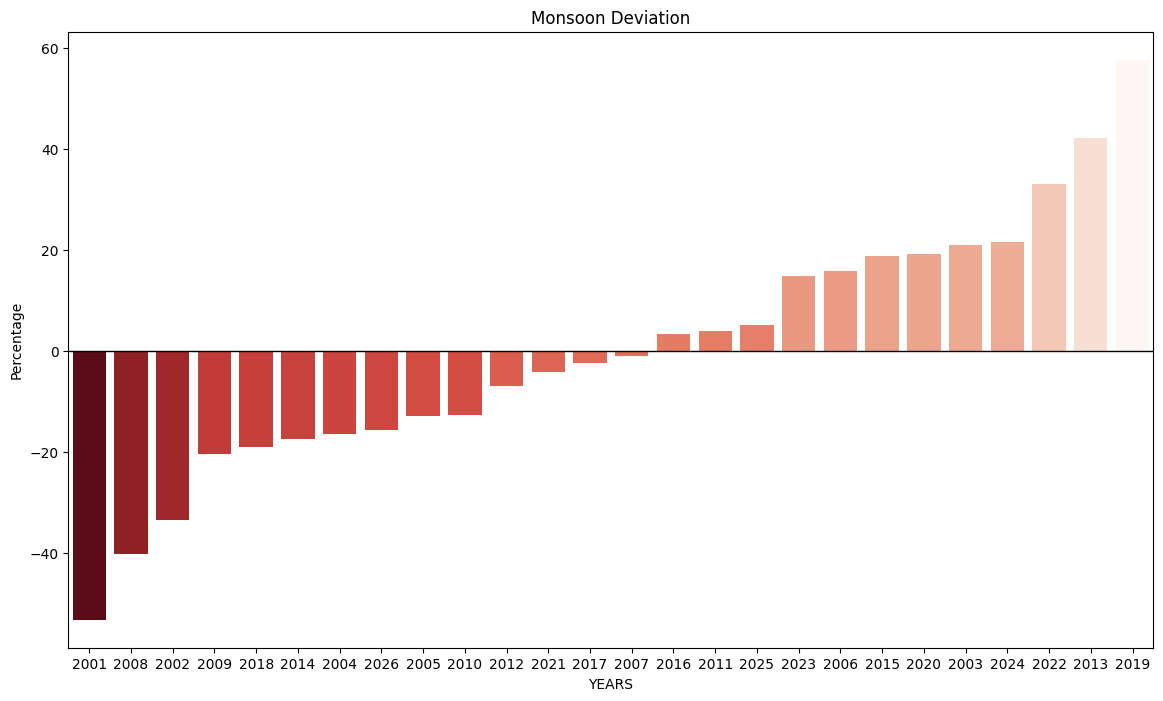

In [39]:
# Monsoon Deviation 
monsoon_deviation = (
    (monsoon_rainfall - average_monsoon)
    / average_monsoon
) * 100
monsoon_deviation = monsoon_deviation.sort_values()
print(monsoon_deviation,"\n")
print("Below Averge : ",len(below_average))
print("Above Averge : ",len(above_average),"\n")

plt.figure(figsize=(14,8))
sns.barplot(
    x = monsoon_deviation.index,
    y = monsoon_deviation.values,
    order = monsoon_deviation.index,
    hue = monsoon_deviation.values,
    palette = 'Reds_r',
    legend = False
)
plt.axhline(y=0, color='black', linewidth=1)
plt.title("Monsoon Deviation")
plt.xlabel("YEARS")
plt.ylabel("Percentage")
plt.show()

In [40]:
# Checking Below Average and above Average Rainfall year-wise

print("Below Averge : ",len(below_average))
print("Above Averge : ",len(above_average),"\n")

below_average_per = len(below_average)/ len(monsoon_rainfall) * 100
above_average_per = len(above_average)/ len(monsoon_rainfall) * 100

print("Below Averge Percentage : ",round(below_average_per, 2))
print("Above Averge Percentage : ",round(above_average_per, 2))

Below Averge :  14
Above Averge :  12 

Below Averge Percentage :  53.85
Above Averge Percentage :  46.15


In [41]:
monsoon_rainfall_mean = monsoon_rainfall.mean()
print("Average Monsoon Rainfall : ",round(monsoon_rainfall_mean, 2),"mm")

Average Monsoon Rainfall :  874.08 mm


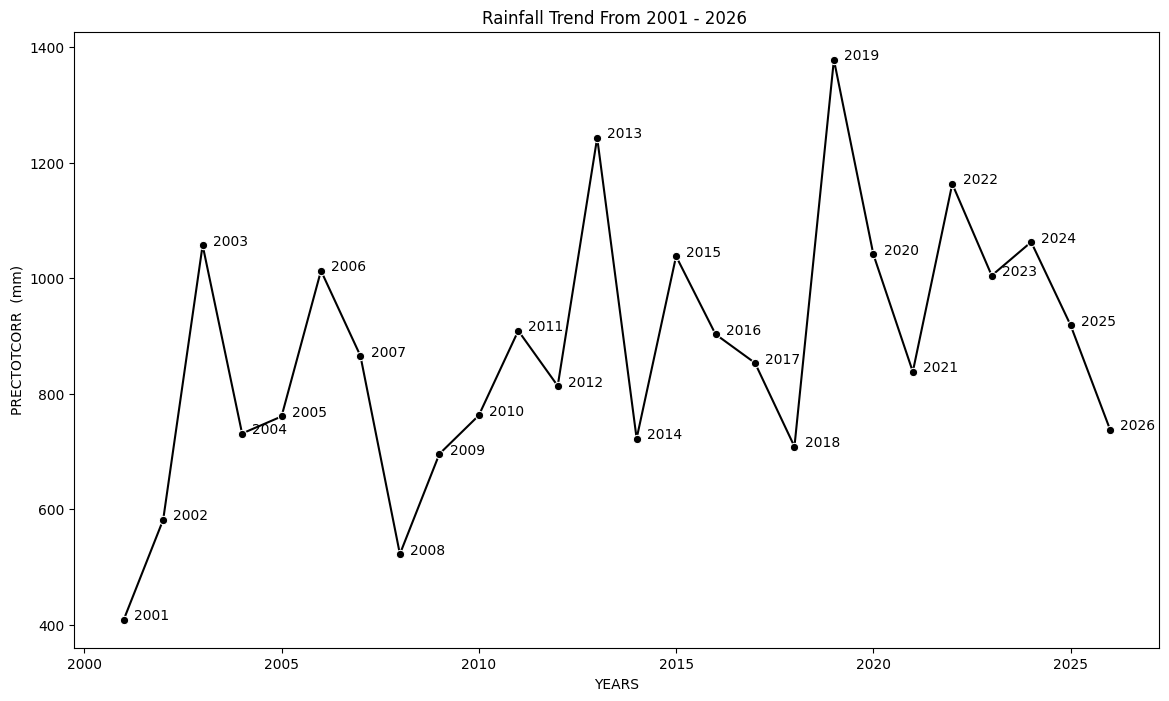

In [42]:
# Trend Analysis of overall Rainfall Year-wise
plt.figure(figsize=(14,8))
sns.lineplot(
    x = monsoon_rainfall.index,
    y = monsoon_rainfall.values,
    marker = "o",
    color = 'black'
)

for x , y in zip(monsoon_rainfall.index, monsoon_rainfall.values):
    plt.annotate(
        str(x),
        (x, y),
        textcoords = "offset points",
        xytext = (20, 0),
        ha = "center"
    )

    
plt.title("Rainfall Trend From 2001 - 2026 ")
plt.xlabel("YEARS")
plt.ylabel("PRECTOTCORR  (mm)")
plt.show()


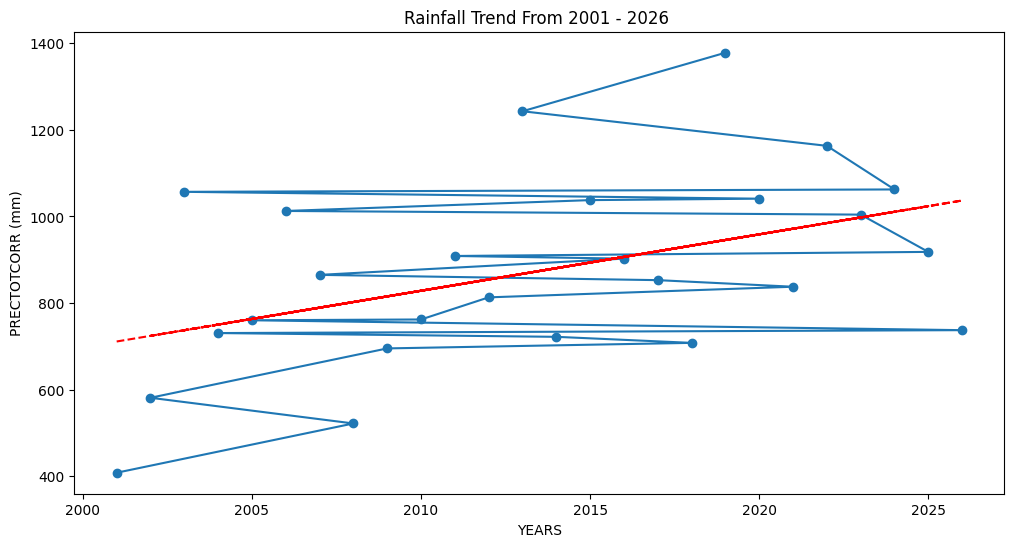

Estimated Yearly Trend : 13.02 mm/year


In [43]:
# Trend Analysis using trend line

years = monsoon_rainfall.index.to_numpy()
rainfall = monsoon_rainfall.to_numpy()

slope , intercept = np.polyfit(years, rainfall, 1)
trend = slope * years + intercept

plt.figure(figsize=(12, 6))

plt.plot(years, rainfall, marker="o", label = "Actul Rainfall")
plt.plot(years, trend, color = "red", linestyle = "--", label = "Trend line")


plt.title("Rainfall Trend From 2001 - 2026 ")
plt.xlabel("YEARS")
plt.ylabel("PRECTOTCORR (mm)")
plt.show()

print(f"Estimated Yearly Trend : {round(slope, 2)} mm/year")

YEAR
2001       NaN
2002    173.03
2003    475.43
2004   -326.04
2005     29.53
2006    252.33
2007   -147.55
2008   -343.03
2009    173.28
2010     66.80
2011    146.59
2012    -95.54
2013    429.63
2014   -520.74
2015    315.59
2016   -135.08
2017    -49.66
2018   -144.80
2019    669.81
2020   -336.97
2021   -203.25
2022    325.27
2023   -158.79
2024     58.11
2025   -144.15
2026   -180.70
Name: PRECTOTCORR, dtype: float64


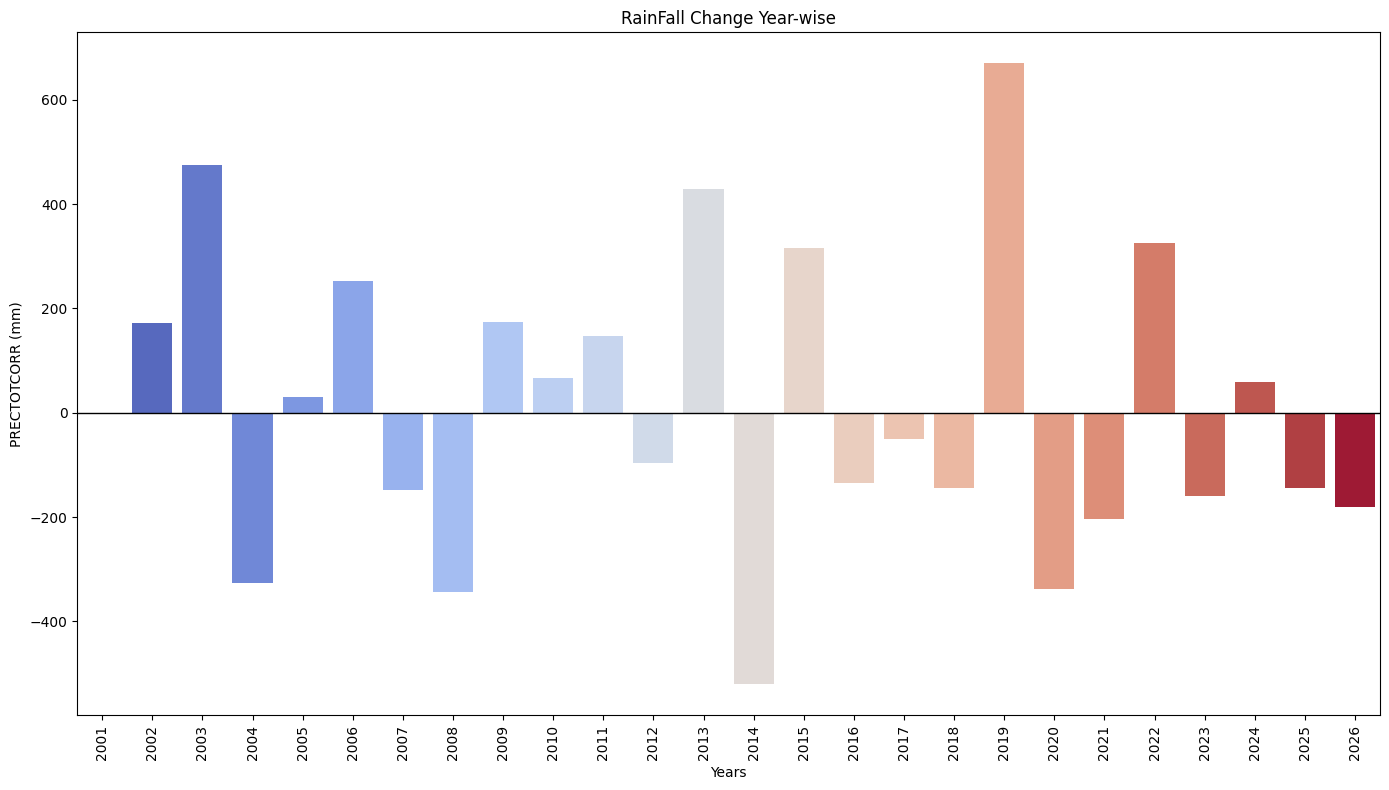

In [44]:
# Checking changes of rainfall year by year

monsoon_rainfall.sort_index(inplace=True)
monsoon_rainfall_shifted = monsoon_rainfall.shift(1)

change = monsoon_rainfall - monsoon_rainfall_shifted
print(change)

plt.figure(figsize=(14,8))
sns.barplot(
    x = change.index,
    y = change.values,
    hue = change.index,
    palette = 'coolwarm',
    legend = False
)
plt.title("RainFall Change Year-wise")
plt.xlabel("Years")
plt.ylabel("PRECTOTCORR (mm)")
plt.axhline(y=0, color='black', linewidth=1)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [45]:
# checking how much time rain increasing and decrease
print("Most Increase: ",change.idxmax()," = ",round(change.max(), 2))
print("Most Decrease: ",change.idxmin()," = ",round(change.min(), 2))


change_decrease = change < 0
change_increae = change > 0
no_change = change == 0

change_decrease = change[change_decrease]
change_increae = change[change_increae]
no_change = change[no_change]

print("Chnage Decrease: ",len(change_decrease))
print("Change Increase: ",len(change_increae))
print("No_change: ",len(no_change))

print("Change Decrease percentage: ",round(len(change_decrease)/len(change)*100, 2),"%")
print("Change Increase percentage: ",round(len(change_increae)/len(change)*100, 2),"%")
print("No_change percentage: ",round(len(no_change)/len(change)*100, 2),"%")


Most Increase:  2019  =  669.81
Most Decrease:  2014  =  -520.74
Chnage Decrease:  13
Change Increase:  12
No_change:  0
Change Decrease percentage:  50.0 %
Change Increase percentage:  46.15 %
No_change percentage:  0.0 %


In [46]:
# Calculating how much monsoon rainfall effect the overall rainfall
monsoon_rainfalls = monsoon_rainfall.sum()
total_rainfall = df['PRECTOTCORR'].sum()

monsoon_Rainfall_percentage = monsoon_rainfalls / total_rainfall * 100

print("Monsoon RainFall out of overall Rainfall : ",round(monsoon_Rainfall_percentage,2))

Monsoon RainFall out of overall Rainfall :  91.43


In [47]:
# Statistical Test
import pymannkendall as mk 

result = mk.original_test(monsoon_rainfall.values)

print("Trend : ",result.trend)
print("P value : ",round(result.p,2))
print("Slope : ",round(result.slope,2))


Trend :  increasing
P value :  0.03
Slope :  13.53


In [48]:
import pandas as pd

df = pd.DataFrame({
    'Item': ['Laptop', 'Mouse', 'Keyboard', 'Monitor', 'Cable'],
    'Price': [50000, 500, 1500, 15000, 200]
})

total_cost = df['Price'].sum()
per_75 = df['Price'].quantile(0.75)
per_50 = df['Price'].quantile(0.50)
def classify(price):
    if price >= per_75:
        return 'High'
    elif price >= per_50:
        return 'Medium'
    else:
        return 'Low'

df['Category'] = df['Price'].apply(classify)
df


,Item,Price,Category
0,Laptop,50000,High
1,Mouse,500,Low
2,Keyboard,1500,Medium
3,Monitor,15000,High
4,Cable,200,Low
